In [1]:
# Baseline simulation (2012–2016)

import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from Alfalfa_Irrigation_Model import full_alfalfa_simulation
df_climate_all = pd.read_csv(
    "../Input/ImperialCounty_ERA5_DailyClimate_2000_2023.csv",
    parse_dates=["Date"]
)
df_climate_all.set_index("Date", inplace=True)
df_climate_all.index = pd.to_datetime(df_climate_all.index)
df_climate_all.sort_index(inplace=True)
df_climate_all.index.name = "Date"
start_climate = pd.Timestamp("2012-01-01")
end_climate = pd.Timestamp("2016-12-31")
df_climate_baseline = df_climate_all[
    (df_climate_all.index >= start_climate) &
    (df_climate_all.index <= end_climate)
].copy()
df_climate_baseline.sort_index(inplace=True)
df_climate_baseline.index.name = "Date"
df_climate_baseline.index.name = "Date"
print("=" * 75)
print("BASELINE CLIMATE")
print("=" * 75)
print(
    f"Full climate file: "
    f"{df_climate_all.index.min().date()} "
    f"to {df_climate_all.index.max().date()}"
)
print(
    f"Selected baseline: "
    f"{df_climate_baseline.index.min().date()} "
    f"to {df_climate_baseline.index.max().date()}"
)
print(
    f"Number of baseline climate rows: "
    f"{len(df_climate_baseline)}"
)

cutting_rows = []
# 2013
# Cutting 0 = establishment / first harvest
wp_2013 = {
    0: 19.6,
    1: 24.5,
    2: 25.0,
    3: 24.3,
    4: 13.2,
    5: 12.6,
    6: 11.4,
    7: 10.2,
    8: 10.2,
    9: 10.2,
    10: 10.2,
    11: 10.2,
    12: 10.2
}
for cutting, wp in wp_2013.items():

    cutting_rows.append({
        "Year": 2013,
        "Cutting": cutting,
        "Water_Productivity": wp,
        "Ky": 1.0
    })

# 2014–2016
wp_regular_year = {
    1: 10.2,
    2: 10.2,
    3: 10.2,
    4: 24.5,
    5: 25.0,
    6: 24.3,
    7: 13.2,
    8: 12.6,
    9: 11.4,
    10: 10.2,
    11: 10.2,
    12: 10.2
}
for year in [2014, 2015, 2016]:
    for cutting, wp in wp_regular_year.items():
        cutting_rows.append({
            "Year": year,
            "Cutting": cutting,
            "Water_Productivity": wp,
            "Ky": 1.0
        })
cutting_param_df = pd.DataFrame(cutting_rows)

stage_lengths = {
    # Establishment / first cutting
    0: [40, 40, 60, 40],
    # Regular cuttings
    1: [5, 10, 10, 5],
    2: [5, 10, 10, 5],
    3: [5, 10, 10, 5],
    4: [5, 10, 10, 5],
    5: [5, 10, 10, 5],
    6: [5, 10, 10, 5],
    7: [5, 10, 10, 5],
    8: [5, 10, 10, 5],
    9: [5, 10, 10, 5],
    10: [5, 10, 10, 5],
    11: [5, 10, 10, 5],
    12: [5, 10, 10, 5]
}

MAX_IRRIGATION_PER_DAY = 25.0
df_result, df_cuttings, df_yearly = full_alfalfa_simulation(
    climate_csv_path=None,
    cutting_param_csv_path=None,
    climate_df=df_climate_baseline,
    cutting_param_df=cutting_param_df,
    output_csv_path=None,
    cutting_yield_output_csv_path=None,
    yearly_yield_output_csv_path=None,
    start_date="2012-10-15",
    years=[
        2012,
        2013,
        2014,
        2015,
        2016
    ],
    et0_method="penman",
    cutting_kc=[
        0.4,
        0.4,
        1.2,
        1.2,
        1.15
    ],
    kc_dormant=0.35,
    kc_harvest_day=0.15,
    kc_post_harvest=0.25,
    kc_pre_harvest_factor=0.6,
    root_depth_mm=1200,
    awc_mm_per_mm=0.12,
    p_depletion=0.5,
    initial_smt_fraction=0.7,
    MAD=0.3,
    refill_target_fraction=1.0,
    survival_threshold_fraction=0.3,
    max_irrigation_per_day=MAX_IRRIGATION_PER_DAY,
    min_infiltration=8,
    use_infiltration_excess=True,
    soil_params={
        "theta_s": 0.4427281,
        "theta_r": 0.1469845,
        "n": 1.170828,
        "K_sat": 1.836049,
        "pwp": 0.14
    },
    temperature_dormancy_threshold=6,
    pre_harvest_no_irrigation_days=3,
    post_cutting_buffer_days=5,
    yield_min_cutting=0.5,
    min_establishment_days=180,
    stage_lengths_by_cutting_number=stage_lengths,
    establishment_cutting=0,
    di_levers={
        "DI_establishment": 1.0,
        "DI_winter": 1.0,
        "DI_spring": 1.0,
        "DI_summer": 1.0,
        "DI_fall": 1.0
    }
)

print("\n")
print("=" * 75)
print("ANNUAL YIELD BY METHOD")
print("=" * 75)
annual_yield_display = df_yearly[
    [
        "Year",
        "Total_Yield_Mg_ha_WP",
        "Total_Yield_Mg_ha_Ky",
        "Total_Yield_Mg_ha_Mitsch"
    ]
].copy()
annual_yield_display[
    [
        "Total_Yield_Mg_ha_WP",
        "Total_Yield_Mg_ha_Ky",
        "Total_Yield_Mg_ha_Mitsch"
    ]
] = annual_yield_display[
    [
        "Total_Yield_Mg_ha_WP",
        "Total_Yield_Mg_ha_Ky",
        "Total_Yield_Mg_ha_Mitsch"
    ]
].round(3)
print(
    annual_yield_display.to_string(
        index=False
    )
)
print("\n")
print("=" * 75)
print("ANNUAL IRRIGATION AND CROP ET")
print("=" * 75)
df_water_annual = df_result.copy()
df_water_annual["Year"] = df_water_annual.index.year
annual_water_display = (
    df_water_annual
    .groupby("Year")
    .agg(
        Total_Irrigation_mm=("Irrigation_mm", "sum"),
        Total_AETc_mm=("AETc", "sum"),
        Total_PETc_mm=("PETc", "sum")
    )
    .reset_index()
)
annual_water_display[
    [
        "Total_Irrigation_mm",
        "Total_AETc_mm",
        "Total_PETc_mm"
    ]
] = annual_water_display[
    [
        "Total_Irrigation_mm",
        "Total_AETc_mm",
        "Total_PETc_mm"
    ]
].round(3)
print(
    annual_water_display.to_string(
        index=False
    )
)

BASELINE CLIMATE
Full climate file: 2000-01-01 to 2023-12-31
Selected baseline: 2012-01-01 to 2016-12-31
Number of baseline climate rows: 1827


ANNUAL YIELD BY METHOD
 Year  Total_Yield_Mg_ha_WP  Total_Yield_Mg_ha_Ky  Total_Yield_Mg_ha_Mitsch
 2013                32.021                32.021                    32.191
 2014                24.440                24.440                    25.308
 2015                23.278                23.278                    23.416
 2016                24.355                24.355                    25.063


ANNUAL IRRIGATION AND CROP ET
 Year  Total_Irrigation_mm  Total_AETc_mm  Total_PETc_mm
 2012              103.942        117.864        117.864
 2013             1523.474       1602.989       1614.247
 2014             1406.685       1470.939       1523.766
 2015             1368.748       1444.813       1456.286
 2016             1431.932       1490.992       1537.229


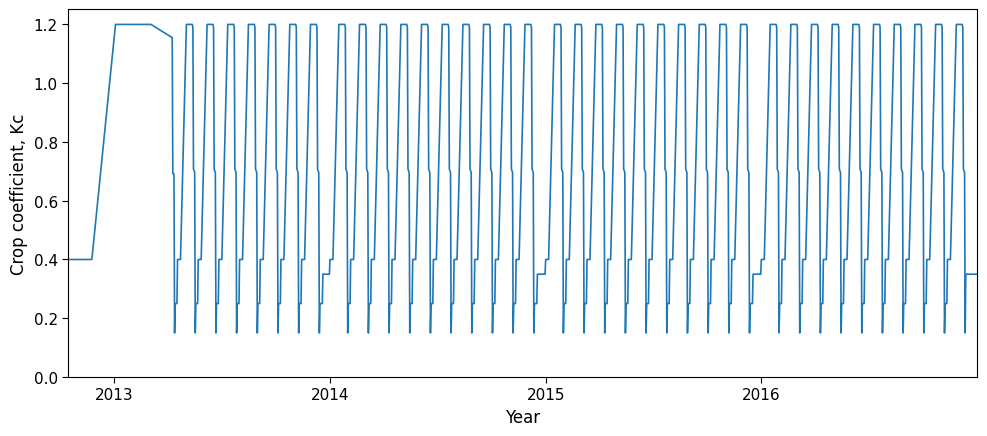

In [2]:
# Figure S4. Simulated daily crop coefficient (Kc), 2012–2016

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_plot = df_result.copy()
df_plot.index = pd.to_datetime(df_plot.index)
df_plot = df_plot.sort_index()

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8
})

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(df_plot.index, df_plot["Kc"], linewidth=1.2)

ax.set_xlabel("Year")
ax.set_ylabel("Crop coefficient, Kc")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_xlim(df_plot.index.min(), df_plot.index.max())
ax.set_ylim(bottom=0)

ax.tick_params(direction="out", length=4, width=0.8)

for spine in ax.spines.values():
    spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

           k = 2.0  k = 2.4  k = 3.0  k = 3.6
AETc/PETc                                    
0.9          0.965    0.973    0.982    0.988
0.8          0.923    0.939    0.957    0.970
0.6          0.808    0.839    0.878    0.910
0.4          0.637    0.679    0.735    0.785


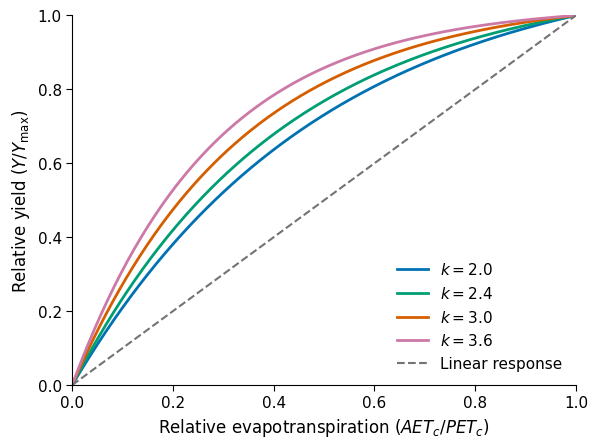

In [3]:
# Figure S5. Sensitivity of the ET–yield response to Mitscherlich curvature

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

def mitsch(r, k):
    return -np.expm1(-k * r) / -np.expm1(-k)

r = np.linspace(0, 1, 300)
r_values = [0.9, 0.8, 0.6, 0.4]
k_values = [2.0, 2.4, 3.0, 3.6]

df_sensitivity = pd.DataFrame(
    {f"k = {k:.1f}": [mitsch(x, k) for x in r_values] for k in k_values},
    index=pd.Index(r_values, name="AETc/PETc")
)
print(df_sensitivity.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.8))

colors = ["#0072B2", "#009E73", "#D55E00", "#CC79A7"]

for k, color in zip(k_values, colors):
    ax.plot(r, mitsch(r, k), color=color, lw=2,
            label=rf"$k = {k:.1f}$")

ax.plot(r, r, color="0.45", ls="--", lw=1.5,
        label="Linear response")

ax.set(
    xlabel=r"Relative evapotranspiration ($AET_c/PET_c$)",
    ylabel=r"Relative yield ($Y/Y_{\max}$)",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", length=4, width=0.8)
ax.legend(frameon=False, loc="lower right")

plt.show()


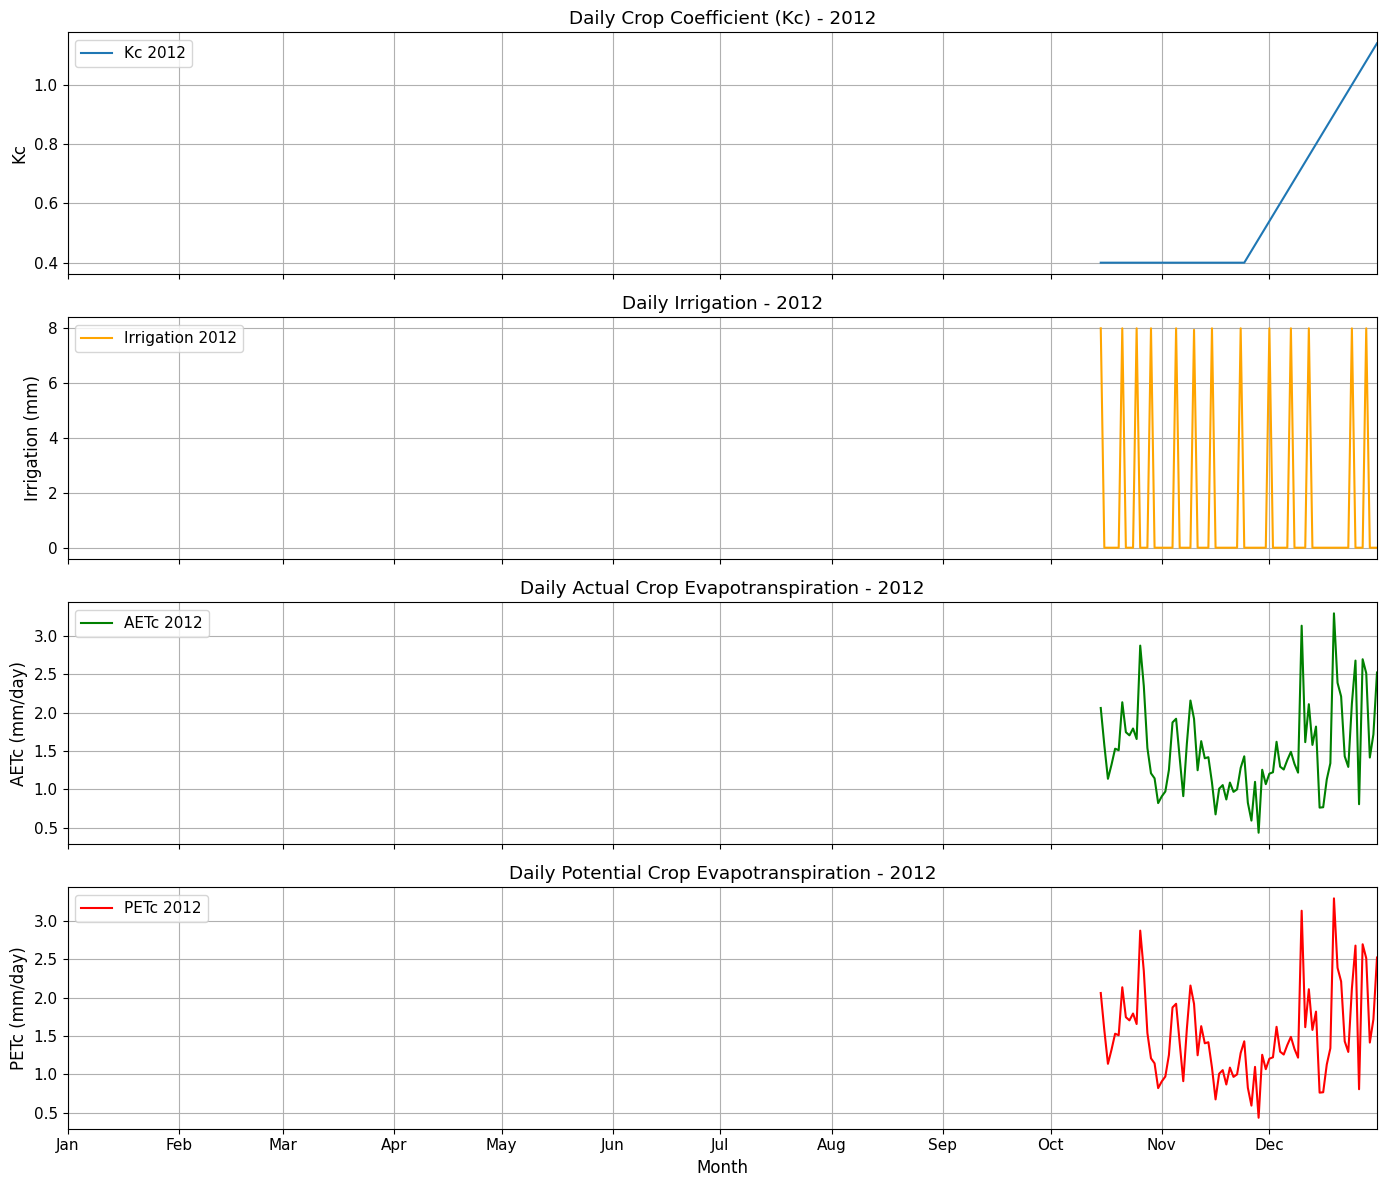

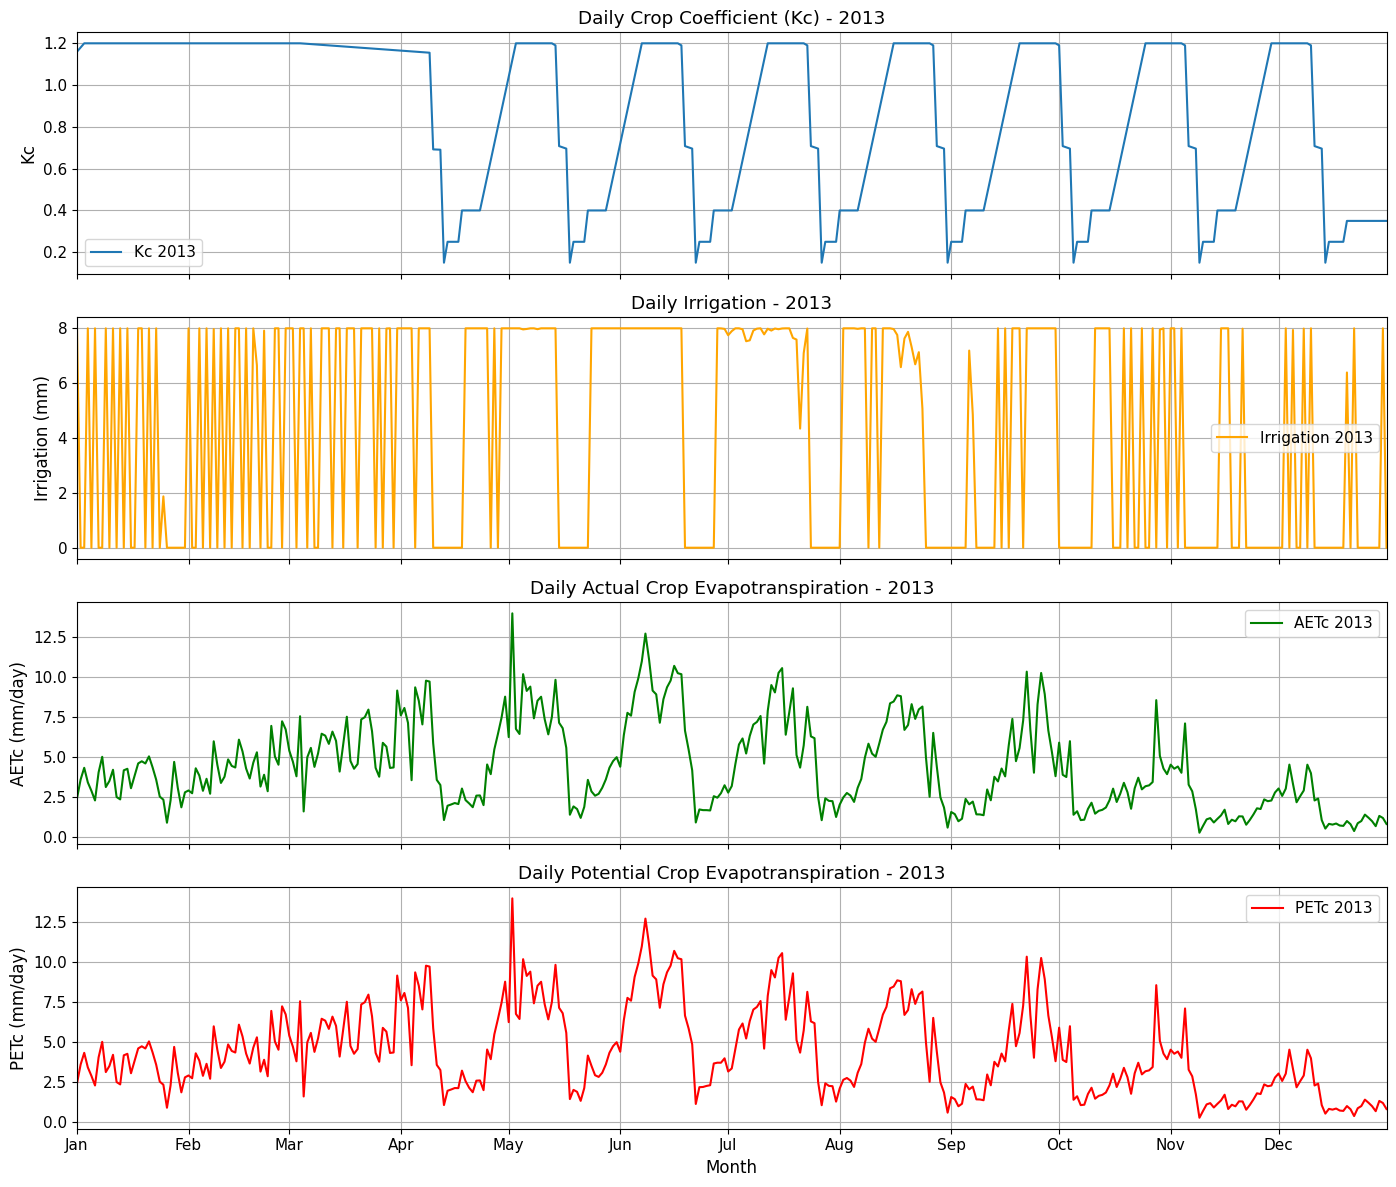

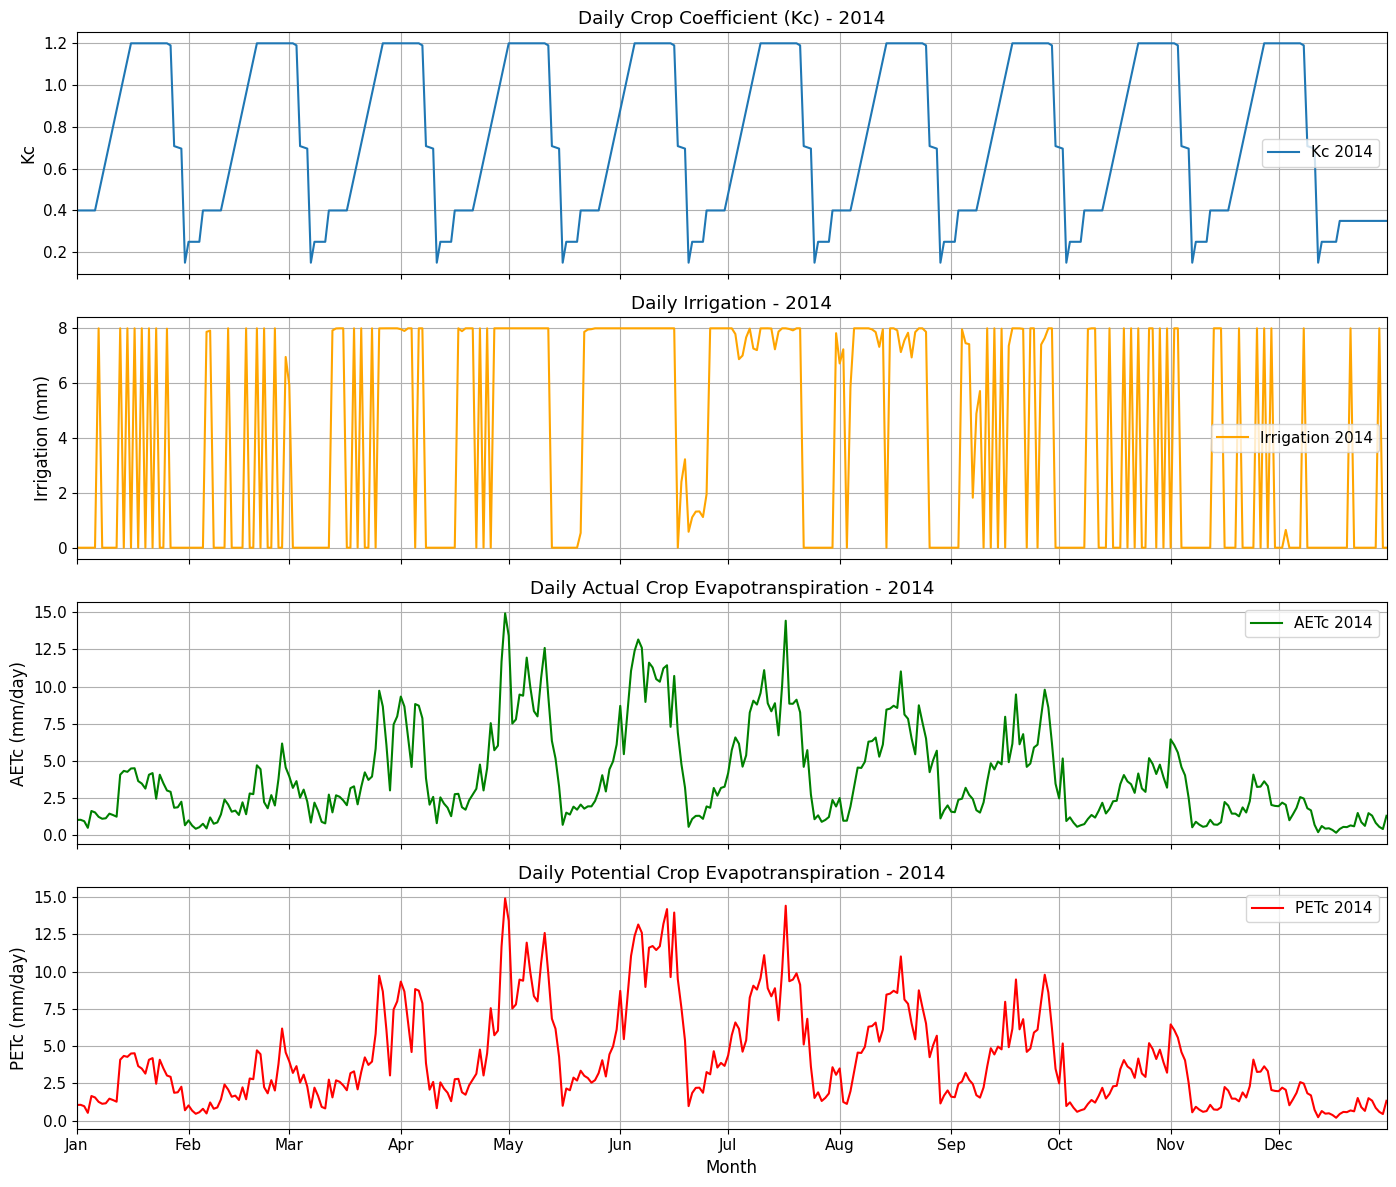

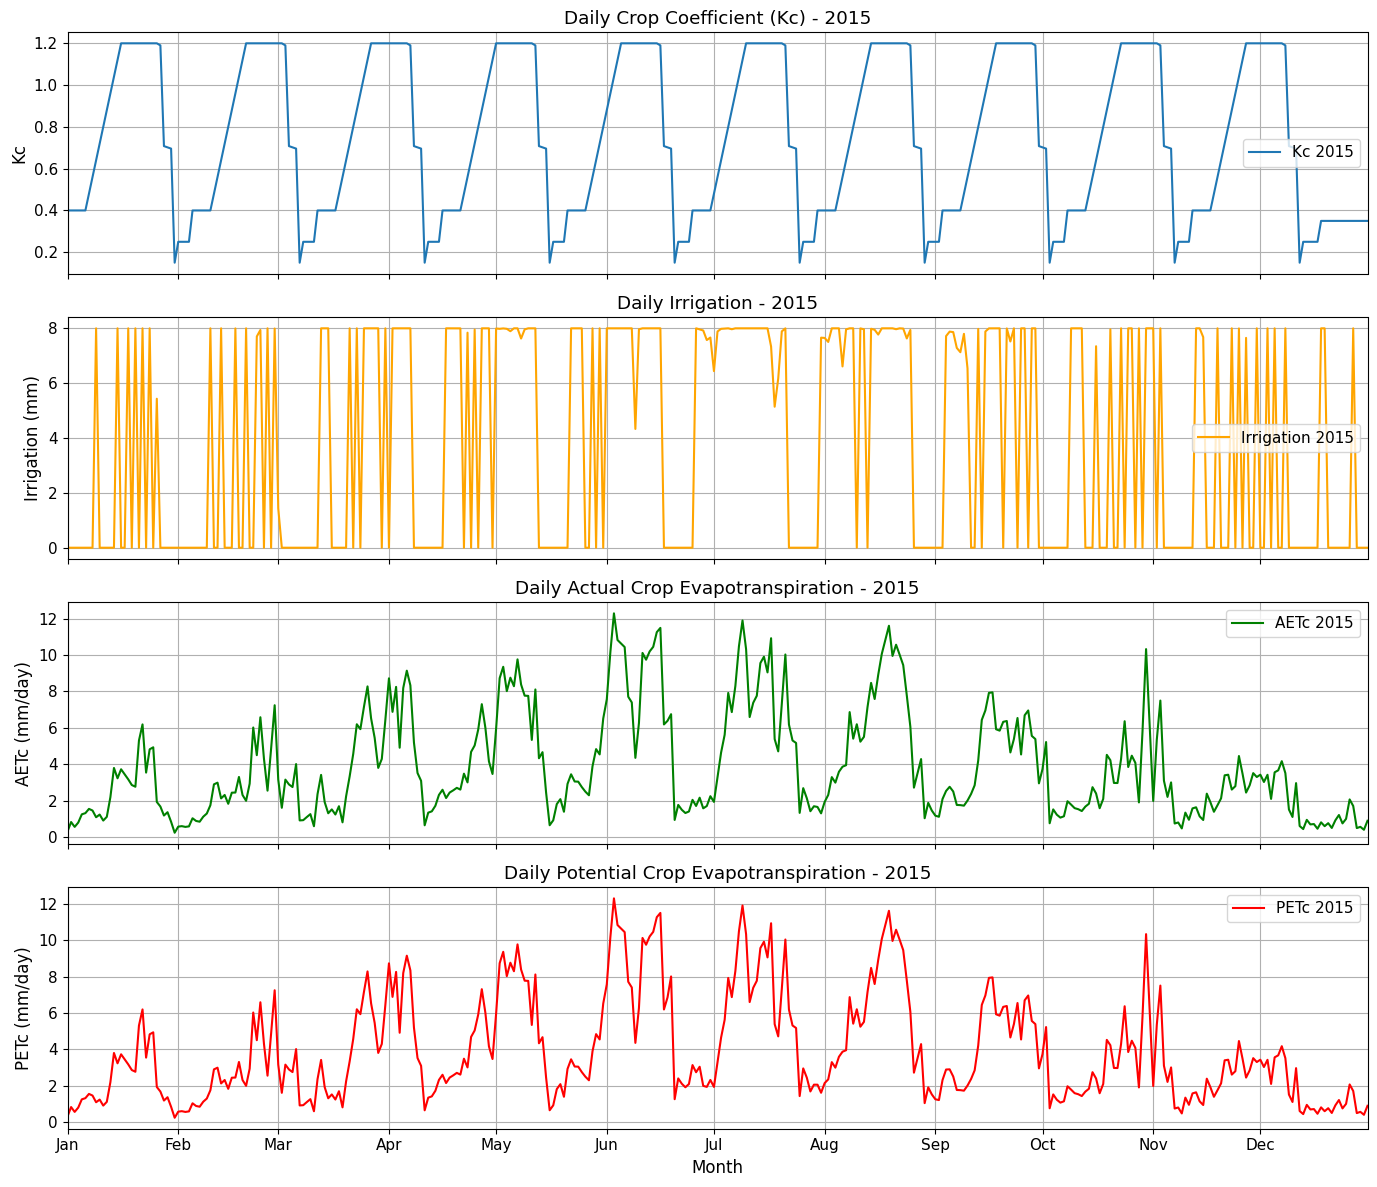

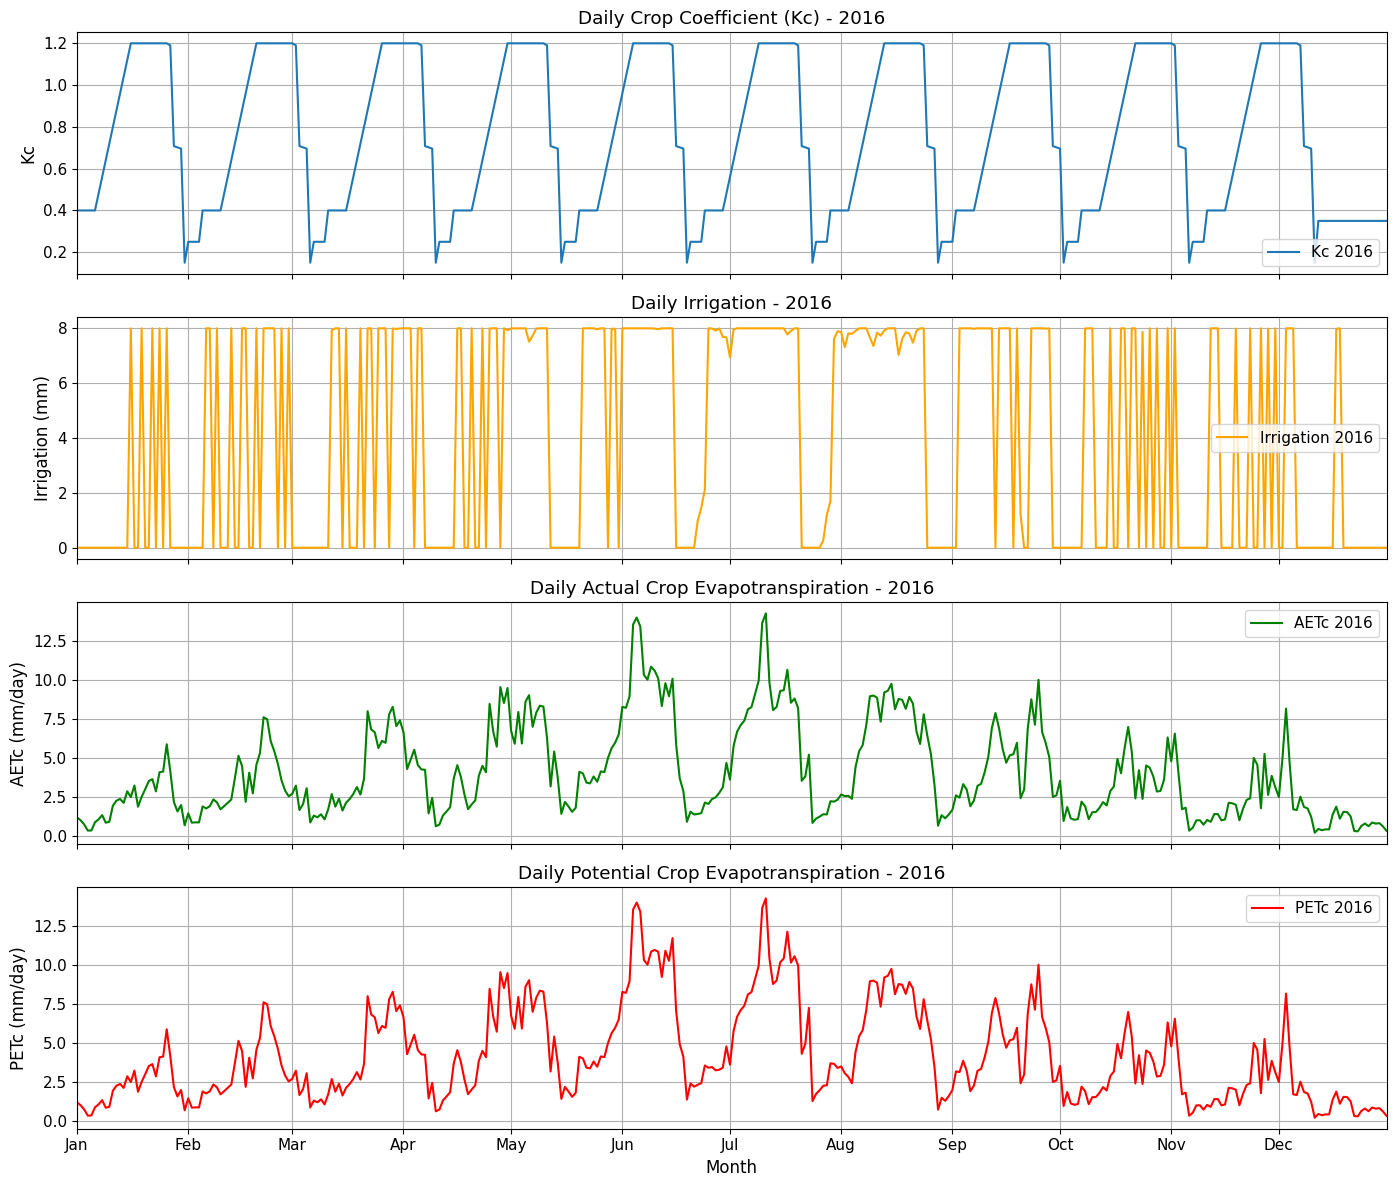

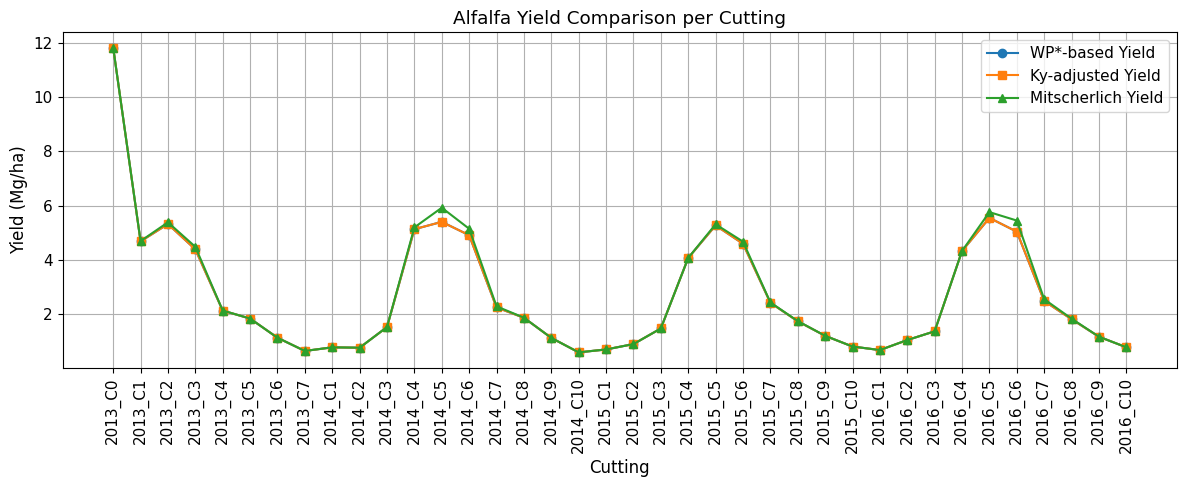

In [4]:
# PLOTS
# 1. DAILY Kc, IRRIGATION, AETc, AND PETc BY YEAR
# 2. YIELD COMPARISON BY CUTTING

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 1. DAILY Kc, IRRIGATION, AETc, AND PETc BY YEAR
def plot_results(df):
    df = df.copy()
    df["year"] = df.index.year
    years = sorted(df["year"].unique())
    for year in years:
        fig, axs = plt.subplots(
            4,
            1,
            figsize=(14, 12),
            sharex=True
        )
        df_year = df[df["year"] == year]

        start_of_year = pd.Timestamp(f"{year}-01-01")
        end_of_year = pd.Timestamp(f"{year}-12-31")
        axs[0].plot(
            df_year.index,
            df_year["Kc"],
            label=f"Kc {year}"
        )
        axs[0].set_ylabel("Kc")
        axs[0].set_title(
            f"Daily Crop Coefficient (Kc) - {year}"
        )
        axs[0].legend()
        axs[0].grid(True)
        axs[0].set_xlim(
            [start_of_year, end_of_year]
        )
        axs[1].plot(
            df_year.index,
            df_year["Irrigation_mm"],
            label=f"Irrigation {year}",
            color="orange"
        )
        axs[1].set_ylabel("Irrigation (mm)")
        axs[1].set_title(
            f"Daily Irrigation - {year}"
        )
        axs[1].legend()
        axs[1].grid(True)
        axs[2].plot(
            df_year.index,
            df_year["AETc"],
            label=f"AETc {year}",
            color="green"
        )
        axs[2].set_ylabel("AETc (mm/day)")
        axs[2].set_title(
            f"Daily Actual Crop Evapotranspiration - {year}"
        )
        axs[2].legend()
        axs[2].grid(True)
        axs[3].plot(
            df_year.index,
            df_year["PETc"],
            label=f"PETc {year}",
            color="red"
        )
        axs[3].set_ylabel("PETc (mm/day)")
        axs[3].set_title(
            f"Daily Potential Crop Evapotranspiration - {year}"
        )
        axs[3].legend()
        axs[3].grid(True)
        for ax in axs:
            ax.set_xlim(
                [start_of_year, end_of_year]
            )
            ax.xaxis.set_major_locator(
                mdates.MonthLocator()
            )
            ax.xaxis.set_major_formatter(
                mdates.DateFormatter("%b")
            )
        axs[3].set_xlabel("Month")
        plt.tight_layout()
        plt.show()

# 2. YIELD COMPARISON BY CUTTING
def plot_yield_comparison(df_cuttings):
    df_plot = df_cuttings.copy()
    df_plot["Cut_Label"] = (
        df_plot["Year"].astype(str)
        + "_C"
        + df_plot["Cutting"].astype(str)
    )
    plt.figure(figsize=(12, 5))
    plt.plot(
        df_plot["Cut_Label"],
        df_plot["Yield_Mg_ha_WP"],
        label="WP*-based Yield",
        marker="o"
    )
    plt.plot(
        df_plot["Cut_Label"],
        df_plot["Yield_Mg_ha_Ky"],
        label="Ky-adjusted Yield",
        marker="s"
    )
    plt.plot(
        df_plot["Cut_Label"],
        df_plot["Yield_Mg_ha_Mitsch"],
        label="Mitscherlich Yield",
        marker="^"
    )
    plt.xticks(rotation=90)
    plt.xlabel("Cutting")
    plt.ylabel("Yield (Mg/ha)")
    plt.title(
        "Alfalfa Yield Comparison per Cutting"
    )
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_results(
    df_result
)
plot_yield_comparison(
    df_cuttings
)
